### Introduction

Sentiment Analysis is a Natural Language Processing (NLP) task that involves analyzing textual data to identify and 

classify opinions as positive or negative. This project aims to develop a machine learning-based sentiment 

classification system using TF-IDF for text feature extraction and Multinomial Naive Bayes and Logistic Regression 

algorithms for classification. The system is trained on movie reviews and evaluated using various performance 

metrics to determine its effectiveness in predicting sentiment from user-provided text.

Import Libraries

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

import warnings
warnings.filterwarnings('ignore')

In [2]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/selam/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/selam/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/selam/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/selam/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/selam/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/selam/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

Load and Inspect dataset

In [3]:
df = pd.read_csv('../NLP_Sentiment_Classification_on_Customer_Reviews/data/sentiment_reviews.csv')

df.head()

,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


In [4]:
df.shape

(10, 3)

In [5]:
df.columns

Index(['review_id', 'review_text', 'sentiment'], dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10 non-null     int64
 1   review_text  10 non-null     str  
 2   sentiment    10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 372.0 bytes


In [7]:
df['sentiment'].value_counts()

sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

Exploratory Data Analysis (EDA)

In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

- There are no null or duplicated values.

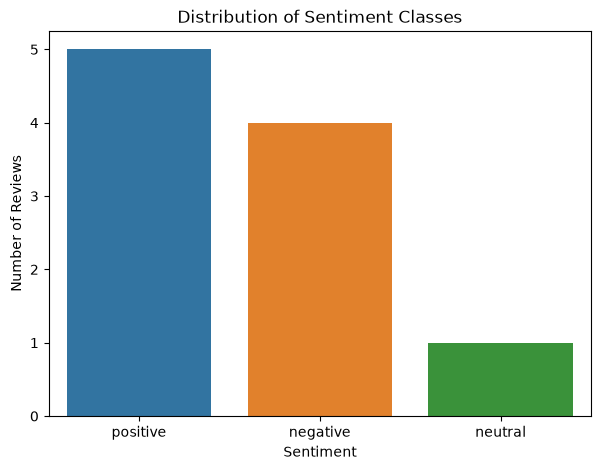

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='sentiment',
    hue='sentiment'
)

plt.title('Distribution of Sentiment Classes')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

- The dataset is not balanced as there is a large number of postive sentiments as compared to the negative and neutral.

In [11]:
# Review Length
df['review_length'] = df['review_text'].apply(
    lambda x: len(str(x).split())
)

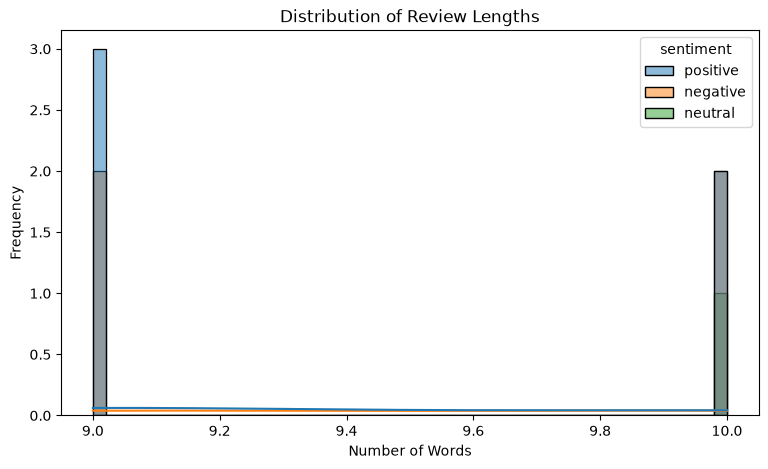

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='review_length',
    hue='sentiment',
    bins=50,
    kde=True
)

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')

plt.show()

Text Preprocessing

In [13]:
stop_words = set(stopwords.words('english'))

# Preserve sentiment-related negation words
stop_words = stop_words - {'not', 'no', 'nor'}

lemmatizer = WordNetLemmatizer()

In [14]:
def preprocess_text(text):

    # Convert text to string
    text = str(text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove numbers, punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords and lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    # Join tokens back into a sentence
    return ' '.join(cleaned_tokens)

In [15]:
# Test preprocessing function
sample_text = """
This movie was AMAZING! I really loved the acting.
It was one of the best movies I've ever watched.
"""

cleaned_text = preprocess_text(sample_text)

print("Original Text:")
print(sample_text)

print("\nPreprocessed Text:")
print(cleaned_text)

Original Text:

This movie was AMAZING! I really loved the acting.
It was one of the best movies I've ever watched.


Preprocessed Text:
movie amazing really loved acting one best movie ever watched


In [16]:
df['cleaned_review'] = df['review_text'].apply(preprocess_text)

In [17]:
df[['review_text', 'cleaned_review', 'sentiment']].head()

,review_text,cleaned_review,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...,negative
2,"Average performance, decent for the price poin...",average performance decent price point nothing...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...,negative


In [18]:
# Analyze most frequent words
from collections import Counter

positive_words = ' '.join(
    df[df['sentiment'] == 'positive']['cleaned_review']
).split()

negative_words = ' '.join(
    df[df['sentiment'] == 'negative']['cleaned_review']
).split()

positive_freq = Counter(positive_words)
negative_freq = Counter(negative_words)

print("Top Positive Words:")
print(positive_freq.most_common(20))

print("\nTop Negative Words:")
print(negative_freq.most_common(20))

Top Positive Words:
[('setup', 2), ('product', 1), ('quality', 1), ('exceptional', 1), ('exceeded', 1), ('expectation', 1), ('absolutely', 1), ('love', 1), ('easy', 1), ('robust', 1), ('work', 1), ('flawlessly', 1), ('customer', 1), ('support', 1), ('helped', 1), ('resolve', 1), ('question', 1), ('within', 1), ('ten', 1), ('minute', 1)]

Top Negative Words:
[('terrible', 1), ('customer', 1), ('service', 1), ('item', 1), ('arrived', 1), ('completely', 1), ('damaged', 1), ('stopped', 1), ('working', 1), ('two', 1), ('day', 1), ('extremely', 1), ('disappointed', 1), ('purchase', 1), ('delivery', 1), ('slow', 1), ('package', 1), ('missing', 1), ('one', 1), ('adapter', 1)]


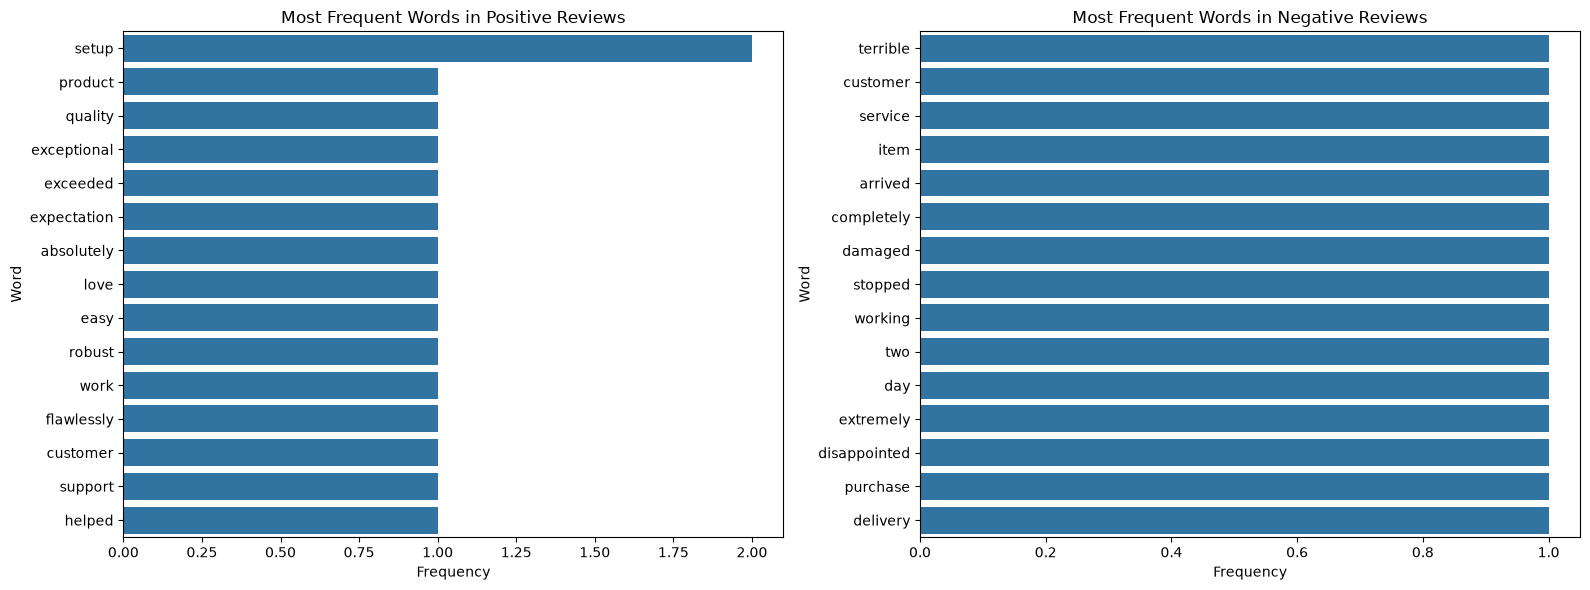

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

positive_freq_df = pd.DataFrame(
    positive_freq.most_common(15),
    columns=['Word', 'Frequency']
)

negative_freq_df = pd.DataFrame(
    negative_freq.most_common(15),
    columns=['Word', 'Frequency']
)

sns.barplot(
    data=positive_freq_df,
    x='Frequency',
    y='Word',
    ax=axes[0]
)

axes[0].set_title('Most Frequent Words in Positive Reviews')

sns.barplot(
    data=negative_freq_df,
    x='Frequency',
    y='Word',
    ax=axes[1]
)

axes[1].set_title('Most Frequent Words in Negative Reviews')

plt.tight_layout()
plt.show()

Convert text into numerical features using TF-IDF

In [20]:
X = df['cleaned_review']
y = df['sentiment']

In [21]:
y = y.map({
    'negative' : 0,
    'neutral' : 1,
    'positive' : 2
})

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [24]:
tfidf = TfidfVectorizer(
    max_features = 5000
)

In [25]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [26]:
X_test_tfidf = tfidf.transform(X_test)

In [27]:
print("Training Matrix:", X_train_tfidf.shape)
print("Testing Matrix:", X_test_tfidf.shape)

Training Matrix: (8, 54)
Testing Matrix: (2, 54)
